# Balanced Gaussian bump

Compare synchronized and primary-only balanced transport on the Gaussian-bump toy.
Both runs reuse the same committed AnnData and frozen cross-modal map. The data and map
are shared with the unbalanced tutorial; this notebook trains only the vector fields.

In [1]:
from pathlib import Path
import sys
import uuid

example_dir = next(parent / "examples" for parent in (Path.cwd(), *Path.cwd().parents)
                   if (parent / "examples" / "synthetic_gaussian_assets.py").is_file())
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

import anndata as ad
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import coati as ct
from gaussian_map import evaluate_bump_map, plot_map_performance
from gaussian_comparison import (
    make_shared_initial_checkpoint,
    plot_gaussian_sync,
    plot_bump_height,
    compare_gaussian_runs,
)
from synthetic_gaussian_assets import load_shared_gaussian_assets, resolve_asset_directory

%matplotlib inline
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
run_dir = Path("outputs") / ("gaussian-bump-" + uuid.uuid4().hex[:8])
run_dir.mkdir(parents=True)
print("Result directory:", run_dir)

Result directory: outputs/gaussian-bump-d6c9946e


## Shared data and map

The repository assets contain 1,000 initial observations and two terminal Gaussian
components of 1,000 observations each. Their covariances are isotropic. The frozen map
was fitted once from the shared observed and support pairs and is not retrained here.

In [2]:
asset_dir = resolve_asset_directory()
cells, T, map_payload = load_shared_gaussian_assets(directory=asset_dir)
map_pairs = ad.read_h5ad(asset_dir / "map_pairs.h5ad")
data = ct.TemporalData.from_anndata(
    cells, obsm_key="X_latent", secondary_obsm_key="X_secondary"
)

summary = cells.obs.groupby(["time", "celltype"], observed=True).size().rename("Cells").to_frame()
assert [len(snapshot) for snapshot in data.primary] == [1000, 2000]
assert not any(parameter.requires_grad for parameter in T.parameters())
summary

Cells
time celltype         
0.0  Initial      1000
1.0  Terminal A   1000
     Terminal B   1000

## Inspect the frozen map

Held-out pair errors and an independent grid check verify the saved map before it is used
to synchronize trajectory training.

,Pairs,XY_RMSE,Z_RMSE,Z_MAE
Evaluation,,,,
Held-out observed,434,0.000047,0.021079,0.004067
Held-out support,1066,0.000065,0.005544,0.003500
Independent grid,9216,0.000067,0.005036,0.002998


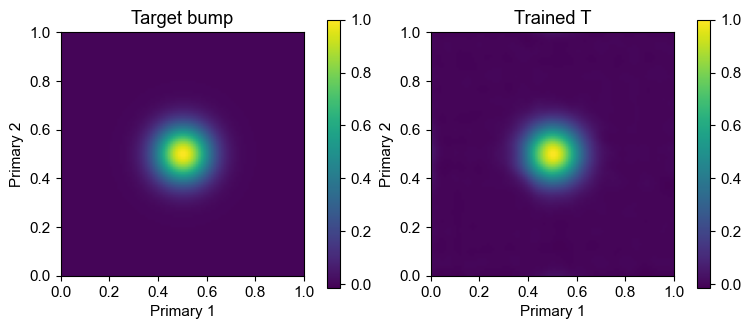

Best validation step: 1500
Grid z correlation: 0.999378
Learned height at (0.5, 0.5): 0.999919


In [3]:
map_scores, map_grid = evaluate_bump_map(T, map_pairs, grid_n=96)
display(map_scores.round(6))
plot_map_performance(map_grid)
plt.show()
print(f"Best validation step: {map_payload['fit']['best_step']}")
print(f"Grid z correlation: {map_grid['z_correlation']:.6f}")
print(f"Learned height at (0.5, 0.5): {map_grid['center_predicted_height']:.6f}")

## Configure balanced transport

`balanced=True` conserves trajectory mass. `secondary_weight=0.5` is the coefficient
Cy for the synchronized run. The primary-only run differs only by disabling synchronization.

In [4]:
config = ct.Config(
    multimodal=True,
    balanced=True,
    iterations=3000,
    batch_size=256,
    hidden_dim=256,
    secondary_weight=.5,
    extra={"median_n_sample": 512, "floor_n_sample": 256, "adaptive_lambda": True},
)
configs = {
    "Without sync": config.with_parameters(multimodal=False, secondary_weight=0.),
    "With sync": config,
}
pd.DataFrame({name: {key: cfg.to_dict()[key] for key in
    ["niters", "num_samples", "hidden_dim", "sync_loss", "sync_weight", "unbalancedModel"]}
    for name, cfg in configs.items()})

,Without sync,With sync
niters,3000,3000
num_samples,256,256
hidden_dim,256,256
sync_loss,False,True
sync_weight,0.0,0.5
unbalancedModel,False,False


## Train the vector fields

The two runs start from the same seeded network weights. Only the synchronized run receives
the frozen map.

In [5]:
initial = make_shared_initial_checkpoint(config, run_dir / "initial.pt")
results = {}
for name, cfg in configs.items():
    print("Training:", name, flush=True)
    results[name] = ct.train_vector_field(
        cells, cfg, use_rep="X_latent", secondary_obsm_key="X_secondary",
        T_model=T if cfg.multimodal else None,
        output_dir=run_dir / ("with_sync" if cfg.multimodal else "without_sync"),
        warm_start_path=initial,
    )

Training: Without sync


Training: With sync


## Learned trajectories

Integrate every initial cell and apply the same frozen map to both primary trajectories.
All paths are shown without route selection or smoothing.

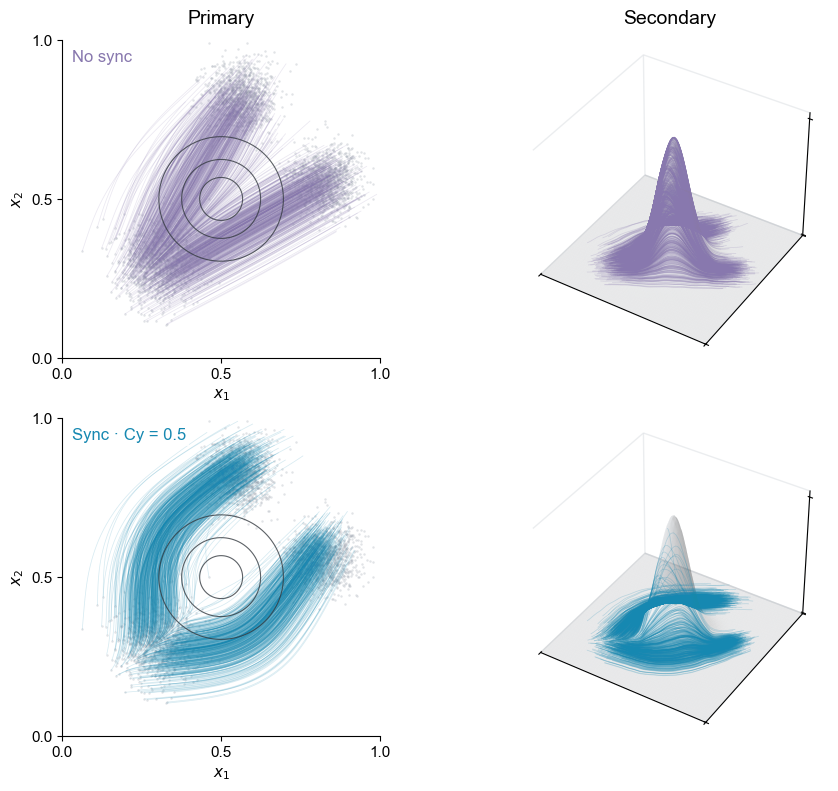

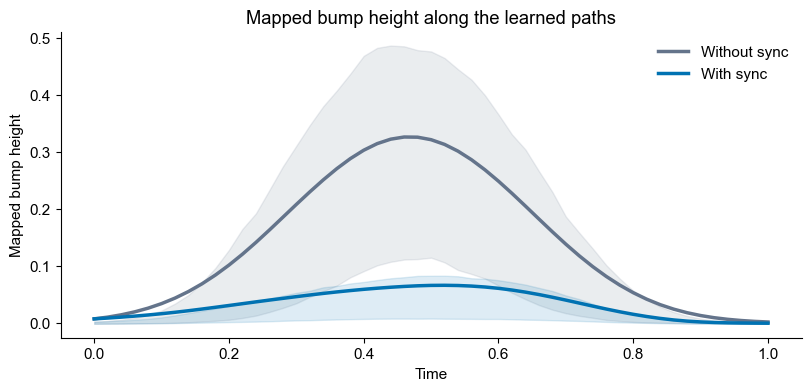

In [6]:
predictions = {}
for name, result in results.items():
    prediction = result.predict_trajectory(times=np.linspace(0., 1., 51), method="rk4")
    with torch.no_grad():
        prediction["secondary"] = T(torch.as_tensor(prediction["primary"], dtype=torch.float32)).numpy()
    predictions[name] = prediction

plot_gaussian_sync(data, T, results, predictions)
plt.show()
plot_bump_height(predictions)
plt.show()

## Diagnostics

In [7]:
scores = compare_gaussian_runs(results, predictions)
scores.T.round(6)

Model,Without sync,With sync
Primary endpoint Sinkhorn,0.000206,0.001425
Primary kinetic energy,0.161313,0.213448
Secondary kinetic energy,0.999115,0.266299
Predicted terminal mass,1.000000,1.000000
Target terminal mass,1.000000,1.000000
Median maximum bump height,0.380628,0.038393
States outside unit square,0.000000,0.000000
